# MIT logo test objects

Loads and plots the `objdata/MIT<N>.csv` (Tmap) / `objdata/MIT<N>_zmap.csv` (zmap) files generated
by `scripts/generate_MIT_logos.jl`, purely to visually confirm they look right -- no forward-model
computation happens here.

Both files stay in the raw `[0,1]` convention `LoadedObject` (`src/prepare.jl`) expects: Tmap has
background at `0.5` (not `0`) and letters at `1.0`, with the original anti-aliased edges preserved;
zmap has background at `0.5` and each of the 3 letters (M, I, T) at its own fixed level
(`0.0`/`0.75`/`1.0`). The artwork is the geometric MIT logo mark, not plain letterforms -- "M" is
actually 3 disjoint vertical bars, "I" a short bar with a fainter anti-aliased lower tail, and "T"
a wide top bar over a narrower stem. `MIT8.csv` has no `_zmap.csv` counterpart: at that resolution
the gaps between M's 3 bars vanish entirely, so there's no reliable way to recover which pixels
belong to which letter (not a practical loss -- production uses `objN = 32`).

In [1]:
cd(isdir("../../End2EndThermalImg.jl") ? "../../End2EndThermalImg.jl" : "../../End2EndThermalImg")
import Pkg
Pkg.activate(".")

  Activating project at `~/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg`


In [2]:
using DelimitedFiles
using PythonPlot

## Load

Picks up every size with a `MIT<N>.csv` in `objdata/`, sorted ascending. `zmap` is `nothing` for any
size with no `_zmap.csv` counterpart (currently just `N=8`).

In [3]:
sizes = sort([parse(Int, m.captures[1]) for f in readdir("objdata")
              for m in [match(r"^MIT(\d+)\.csv$", f)] if m !== nothing])
println("sizes = ", sizes)

Tmaps = Dict(N => Matrix{Float64}(readdlm("objdata/MIT$(N).csv", ',', Float64)) for N in sizes)
zmaps = Dict(N => (isfile("objdata/MIT$(N)_zmap.csv") ? Matrix{Float64}(readdlm("objdata/MIT$(N)_zmap.csv", ',', Float64)) : nothing)
             for N in sizes)

for N in sizes
    println("N=$N  Tmap extrema=", extrema(Tmaps[N]),
            zmaps[N] === nothing ? "  zmap=none" : "  zmap unique values=$(sort(unique(zmaps[N])))")
end

sizes = [8, 16, 32, 64, 96, 128, 256]
N=8  Tmap extrema=(0.5, 1.0)  zmap=none
N=16  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]
N=32  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]
N=64  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]
N=96  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]
N=128  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]
N=256  Tmap extrema=(0.5, 1.0)  zmap unique values=[0.0, 0.5, 0.75, 1.0]


## Plot

Tmap and zmap side by side for every size that has both; `MIT8` (Tmap only) is shown separately
at the end.

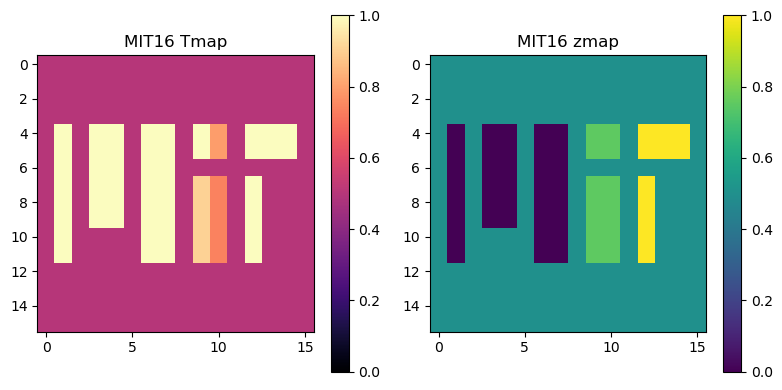

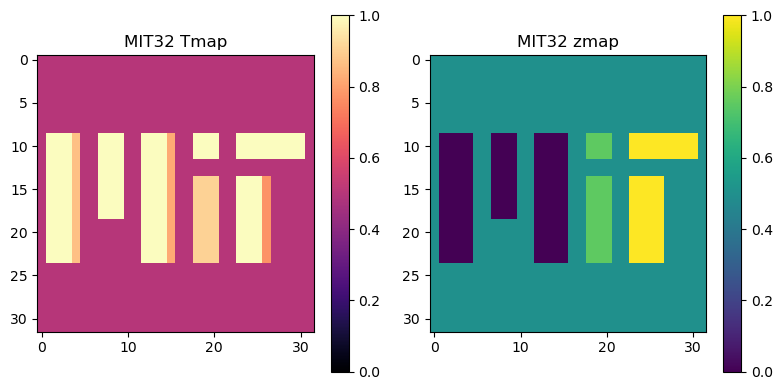

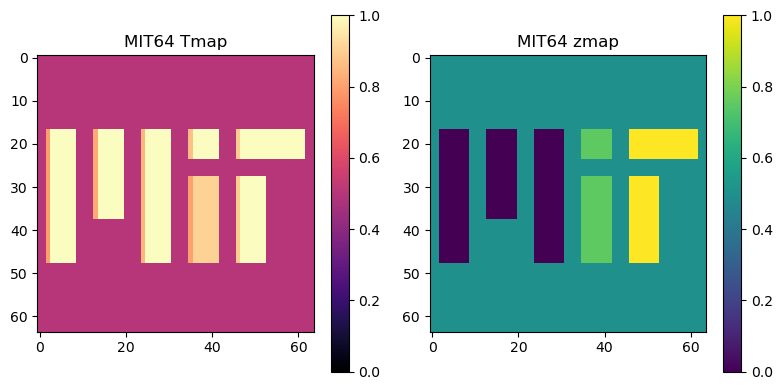

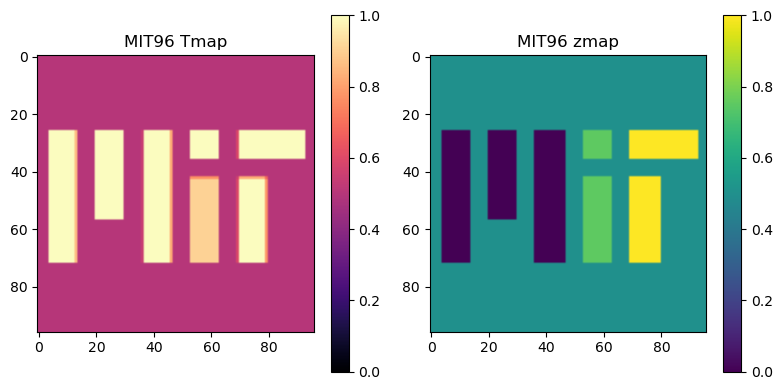

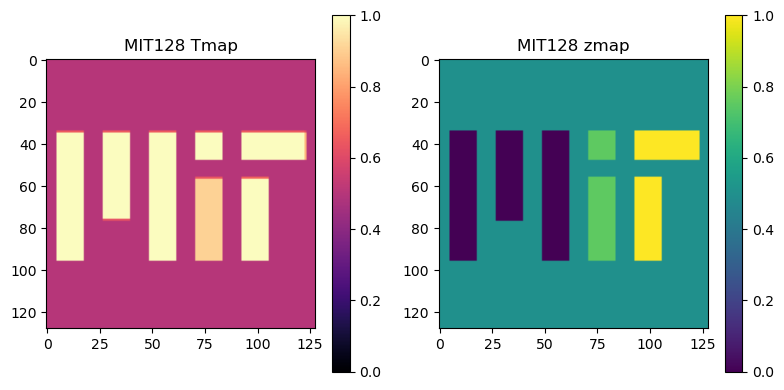

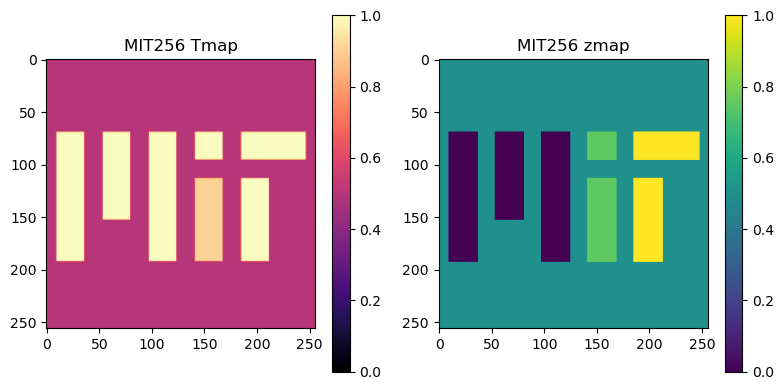

In [4]:
for N in sizes
    zmaps[N] === nothing && continue
    fig, axes = subplots(1, 2; figsize=(8, 4))
    im0 = axes[0].imshow(Tmaps[N], cmap="magma", vmin=0, vmax=1)
    axes[0].set_title("MIT$(N) Tmap")
    fig.colorbar(im0, ax=axes[0])
    im1 = axes[1].imshow(zmaps[N], cmap="viridis", vmin=0, vmax=1)
    axes[1].set_title("MIT$(N) zmap")
    fig.colorbar(im1, ax=axes[1])
    fig.tight_layout()
    display(fig)
end

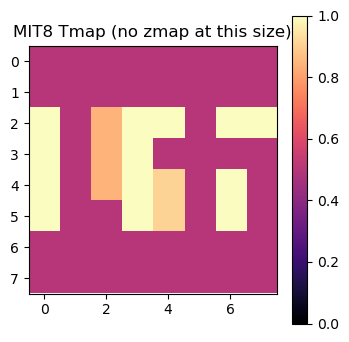

In [5]:
fig, ax = subplots(figsize=(4, 4))
im = ax.imshow(Tmaps[8], cmap="magma", vmin=0, vmax=1)
ax.set_title("MIT8 Tmap (no zmap at this size)")
fig.colorbar(im, ax=ax)
fig;